## Trip Advisor reviews using the dataset to decide the positive or negative predict the review.

#### Pipeline:
### Review Data → Cleaning → Text Preprocessing → TF-IDF → Train/Test Split → Naive Bayes → Prediction → Evaluation

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import pandas as pd

In [4]:
pd.read_csv(r"C:\Users\user\Desktop\MLA\Trip_advisor_review.csv")


,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5
...,...,...
20486,"best kept secret 3rd time staying charm, not 5...",5
20487,great location price view hotel great quick pl...,4
20488,"ok just looks nice modern outside, desk staff ...",2
20489,hotel theft ruined vacation hotel opened sept ...,1


In [5]:
df=pd.read_csv(r"C:\Users\user\Desktop\MLA\Trip_advisor_review.csv")
df


,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5
...,...,...
20486,"best kept secret 3rd time staying charm, not 5...",5
20487,great location price view hotel great quick pl...,4
20488,"ok just looks nice modern outside, desk staff ...",2
20489,hotel theft ruined vacation hotel opened sept ...,1


In [6]:
df.head()

,Review,Rating
0,nice hotel expensive parking got good deal sta...,4
1,ok nothing special charge diamond member hilto...,2
2,nice rooms not 4* experience hotel monaco seat...,3
3,"unique, great stay, wonderful time hotel monac...",5
4,"great stay great stay, went seahawk game aweso...",5


In [7]:
df.shape

(20491, 2)

In [8]:
df.columns

Index(['Review', 'Rating'], dtype='object')

In [9]:
df['Rating'].value_counts()

Rating
5    9054
4    6039
3    2184
2    1793
1    1421
Name: count, dtype: int64

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20491 entries, 0 to 20490
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  20491 non-null  object
 1   Rating  20491 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 320.3+ KB


In [11]:
df.isnull().sum()

Review    0
Rating    0
dtype: int64

# sentiment columns

In [12]:
df['Sentiment']=df['Rating'].apply(
    lambda x: 'Positive' if x >=4 else 'Negative')


In [13]:
df[['Review','Rating','Sentiment']].head()

,Review,Rating,Sentiment
0,nice hotel expensive parking got good deal sta...,4,Positive
1,ok nothing special charge diamond member hilto...,2,Negative
2,nice rooms not 4* experience hotel monaco seat...,3,Negative
3,"unique, great stay, wonderful time hotel monac...",5,Positive
4,"great stay great stay, went seahawk game aweso...",5,Positive


In [14]:
df['Sentiment'].value_counts()

Sentiment
Positive    15093
Negative     5398
Name: count, dtype: int64

In [15]:
x=df["Review"]
y=df["Sentiment"]

# train test split

In [16]:
X = df["Review"].astype(str)
y = df["Sentiment"]

# Check
print("X created:", X.shape)
print("y created:", y.shape)
print(X.head())
print(y.head())

X created: (20491,)
y created: (20491,)
0    nice hotel expensive parking got good deal sta...
1    ok nothing special charge diamond member hilto...
2    nice rooms not 4* experience hotel monaco seat...
3    unique, great stay, wonderful time hotel monac...
4    great stay great stay, went seahawk game aweso...
Name: Review, dtype: object
0    Positive
1    Negative
2    Negative
3    Positive
4    Positive
Name: Sentiment, dtype: object


# train test  split

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16392,)
X_test: (4099,)
y_train: (16392,)
y_test: (4099,)


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("X_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf:", X_test_tfidf.shape)

X_train_tfidf: (16392, 5000)
X_test_tfidf: (4099, 5000)


In [19]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [20]:
y_pred = nb_model.predict(X_test_tfidf)

print(y_pred[:10])

['Positive' 'Negative' 'Positive' 'Positive' 'Positive' 'Positive'
 'Positive' 'Positive' 'Negative' 'Positive']


In [21]:
review = ["The hotel was excellent and I really enjoyed my stay"]

review_tfidf = tfidf.transform(review)

prediction = nb_model.predict(review_tfidf)

print("Sentiment:", prediction[0])

Sentiment: Positive


In [22]:
review = ["The hotel room was dirty and the service was very bad"]

review_tfidf = tfidf.transform(review)

prediction = nb_model.predict(review_tfidf)

print("Sentiment:", prediction[0])

Sentiment: Negative


In [23]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.86069773115394

Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.55      0.68      1080
    Positive       0.86      0.97      0.91      3019

    accuracy                           0.86      4099
   macro avg       0.87      0.76      0.79      4099
weighted avg       0.86      0.86      0.85      4099



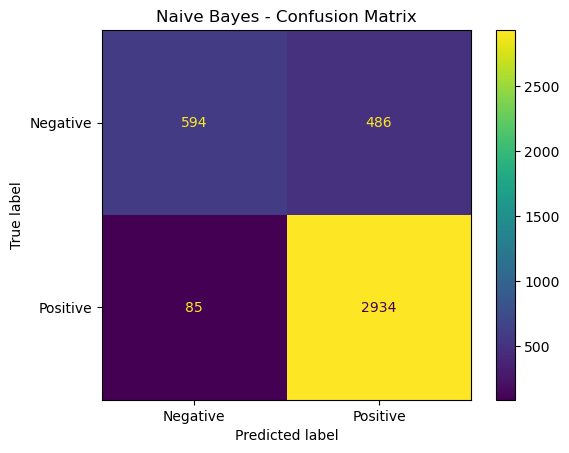

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Naive Bayes - Confusion Matrix")
plt.show()

# hyperparamaneter tunings

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

alphas = [0.01, 0.1, 0.5, 1, 2, 5]

for alpha in alphas:
    model = MultinomialNB(alpha=alpha)
    model.fit(X_train_tfidf, y_train)
    
    pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, pred)
    
    print("Alpha:", alpha, "Accuracy:", round(acc, 4))

Alpha: 0.01 Accuracy: 0.8668
Alpha: 0.1 Accuracy: 0.8666
Alpha: 0.5 Accuracy: 0.8634
Alpha: 1 Accuracy: 0.8607
Alpha: 2 Accuracy: 0.8517
Alpha: 5 Accuracy: 0.8131


In [26]:
best_alpha = 0.5   
final_nb = MultinomialNB(alpha=best_alpha)

final_nb.fit(X_train_tfidf, y_train)

final_pred = final_nb.predict(X_test_tfidf)

print("Final Naive Bayes model trained successfully!")

Final Naive Bayes model trained successfully!


In [27]:
from sklearn.metrics import accuracy_score, classification_report

print("Final Accuracy:", accuracy_score(y_test, final_pred))

print("\nFinal Classification Report:")
print(classification_report(y_test, final_pred))

Final Accuracy: 0.8633813125152476

Final Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.57      0.69      1080
    Positive       0.86      0.97      0.91      3019

    accuracy                           0.86      4099
   macro avg       0.86      0.77      0.80      4099
weighted avg       0.86      0.86      0.85      4099



In [28]:
review = ["The hotel was excellent and I really enjoyed my stay"]

review_tfidf = tfidf.transform(review)

prediction = final_nb.predict(review_tfidf)

print("Review:", review[0])
print("Predicted Sentiment:", prediction[0])

Review: The hotel was excellent and I really enjoyed my stay
Predicted Sentiment: Positive


In [29]:
review = ["The hotel was dirty and the service was very bad"]

review_tfidf = tfidf.transform(review)

prediction = final_nb.predict(review_tfidf)

print("Review:", review[0])
print("Predicted Sentiment:", prediction[0])

Review: The hotel was dirty and the service was very bad
Predicted Sentiment: Negative


In [32]:
review = ["The hotel was clean and the service was very good"]

review_tfidf = tfidf.transform(review)

prediction = final_nb.predict(review_tfidf)

print("Review:", review[0])
print("Predicted Sentiment:", prediction[0])

Review: The hotel was clean and the service was very good
Predicted Sentiment: Positive
